In [1]:
theta = [50000, 75000, 0.4116, 111900, 9905, 30000]
theta_n = [100000, 100000, 1, 100000, 100, 10000]
theta_mins = [10000, 0, 0.1, 50000, 10, 10000]
theta_maxs = [1000000, 200000, 10, 200000, 10000, 200000]

In [2]:
system = {
    'tvi': {  # Time-variant input variables (models input: tvi), each key is a symbol nad key in tvi as well
        'u1': {  # Temperature (K)
            'stps': 6,  # Number of switching times in CVPs (vector parametrisation resolution in time dimension):
            # Must be a positive integer > 1. swps-1 is the number of steps
            'const': 'rel',  # Constraint type: relative state of signal levels in CVPs
            # 'rel' (relative) ensures relaxation, 'dec' (decreasing) ensures decreasing signal levels, 'inc' (increasing) ensures increasing signal levels
            'max': 306.15,  # Maximum allowable signal level, des_opt space upper bound
            'min': 296.15,  # Minimum allowable signal level, des_opt space lower bound
            'cvp': 'LPF',  # Design CVP method (CPF - constant profile, LPF - linear profile)
            'offl': 0.05,  # minimum allowed perturbation of signal (ratio)
            'offt': 0.5  # minimum allowed perturbation of time (ratio)
        },
    },
    'tvo': {  # Time-variant output variables (responses, measured or unmeasured)
        'y1': {  # response variable, here carbonation efficiency
            'init': 0,  # Initial value for the response variable, it can be a value, or 'variable' for case it is a des_opt decision (time-invariant input variable)
            'meas': True,  # Flag indicating if this variable is directly measurable, if False, it is a virtual output
            'sp': 10,  # the amound of samples per each round (run)
            'unc': 0.005,  # amount of noise (standard deviation) in the measurement, in case of insilico, this is used for simulating a normal distribution of noise to measurement (only measurement)
            'offt': 0.3,  # minimum allowed perturbation of sampling times (ratio)
            'samp_s': 1,  # Matching criterion for models prediction and data alignment
            'samp_f': [0, 16],  # fixed sampling times
        },
        'y2': {  # response variable, here carbonation efficiency
            'init': 0,  # Initial value for the response variable, it can be a value, or 'variable' for case it is a des_opt decision (time-invariant input variable)
            'meas': True,  # Flag indicating if this variable is directly measurable, if False, it is a virtual output
            'sp': 10,  # the amound of samples per each round (run)
            'unc': 0.005,  # amount of noise (standard deviation) in the measurement, in case of insilico, this is used for simulating a normal distribution of noise to measurement (only measurement)
            'offt': 0.3,  # minimum allowed perturbation of sampling times (ratio)
            'samp_s': 1,  # Matching criterion for models prediction and data alignment
            'samp_f': [0, 16],  # fixed sampling times
        },
        'y3': {  # response variable, here carbonation efficiency
            'init': 0,
            # Initial value for the response variable, it can be a value, or 'variable' for case it is a des_opt decision (time-invariant input variable)
            'meas': True,
            # Flag indicating if this variable is directly measurable, if False, it is a virtual output
            'sp': 10,  # the amound of samples per each round (run)
            'unc': 0.005,
            # amount of noise (standard deviation) in the measurement, in case of insilico, this is used for simulating a normal distribution of noise to measurement (only measurement)
            'offt': 0.3,  # minimum allowed perturbation of sampling times (ratio)
            'samp_s': 1,  # Matching criterion for models prediction and data alignment
            'samp_f': [0, 16],  # fixed sampling times
        },
    },
    'tii': {  # Time-invariant input variables (tii)
        'y10': {  # 1st symbolic time-invariant control, Density of solid reactant (kg/m³)
            'max': 1,  # Maximum allowable signal level, des_opt space upper bound
            'min': 0.3  # Minimum allowable signal level, des_opt space upper bound
        },
        'y20': {  # 1st symbolic time-invariant control, Density of solid reactant (kg/m³)
            'max': 1,  # Maximum allowable signal level, des_opt space upper bound
            'min': 0.19  # Minimum allowable signal level, des_opt space upper bound
        },
    },
    'tio': {  # Time-invariant output variables (empty here, could hold steady state responses that hold no dependency)
    },
    't_s': [0, 16],  # Time span  (600 s to 10,800 s), duration of numerical perturbations (the rest is precluded from des_opt)
    't_r': 0.02,  # Time resolution (10 s), minimum time steps for the simulation/des_opt/controls
    't_d': 0.3
}

models = { # Settings related to the rival models and their parameters
    'can_m': ['M'],  # Active solvers (rival models) to be used in the experiment
    'krt': {'M': 'pys'},  # Kernel type for each model, 'pys' for python standalone scripts, 'pym' for middoe.krnl_models, 'gpr' for gPAS models
    # type of the model interface, 'pym' for middoe.krnl_models, 'gpr' for gPAS models, function name for globally defined functions, 'pys' for python standalone scripts
    'creds': {'M': '@@TTmnoa698'},
    # credentials for gPAS models, if not needed, leave empty
    'src': {'M': 'C:/Users/Tadmin/PycharmProjects/middoe/tests/paper3/cs2/SEM+SEM-ext/model.py'},
    # for now for gPAS readable files, or python standalone scripts

    'theta': { # Theta parameters for each models
        'M': theta_n
    },
    't_u': { # Maximum bounds for theta parameters (based on normalized to'f20': theta20mins, 1)
        'M': theta_maxs
    },
    't_l': { # Minimum bounds for theta parameters (based on normalized to 1)
        'M': theta_mins
    },
    'mutation': { # Mutation settings for each model
        'M': [False, False, True, True, True, True]  # Mutation for each parameter in the model
    }
}

In [3]:
insilicos = { # Settings for the insilico data generation
    'tr_m': 'M', # selected true models (with nominal values)
    'theta': theta,
    'errt': 'abs',  # error type, 'rel' for relative error, 'abs' for absolute error
    'prels': { # classic des_opt settings, sheet name is the round run name, each sheet contains the data for the round, iso space.
    }
}

In [4]:
des_opt = { # Design settings for the experiment
    'eps': 1e-5, #perturbation size of parameters in SA FDM method (in a normalized to 1 space)
    'md_ob': 'BFF',     # MD optimality criterion, 'HR': Hunter and Reiner, 'BFF': Buzzi-Ferraris and Forzatti
    'pp_ob': 'SEM',  # PP optimality criterion, 'D', 'A', 'E', 'ME'
    'plt': True,  # Plot the results
    'meth': 'PS',
    # optimisation method, 'G': Global Differential Evolution, 'L': Local Pattern Search, 'GL': Global Differential Evolution refined with Local Pattern Search
    'conv_rep': True,        # report optimisation convergence metrics
    'priors': False,    # prior information included

    'itr': {
        'pps': 50, # population size
        'maxmd': 5, # maximum number of MD runs
        'tolmd': 1, # tolerance for MD optimization
        'maxpp':50 ,# maximum number of PP runs
        'tolpp': 1, # tolerance for PP optimization
    }
}

In [5]:
iden_opt = { # Settings for the parameter estimation process
    'meth': 'TC',  #'SLSQP', 'SQP', 'DE', 'NM', 'BFGS', 'LBFGSB'
    'ms': True, # multi starting   # True or False
    'maxit': 500,
    'tol': 0.1,
    'sens_m': 'central', # 'central',  and 'forward' for FDM precision
    'var-cov': 'M', # 'H' for based on hessidan, and 'M' for based on fisher
    'nboot':50,
    'init': None,   # use 'rand' to have random starting point and use None to start from theta_parameters nominal values (to be avoided in insilico studies)
    'eps': 1e-5,  # perturbation size of parameters in SA FDM method (in a normalized to 1 space)e-
    #usually 1e-3, or None to perform a mesh independency test, and auto adjustment
    'ob': 'WLS',  #loss function, 'LS': least squares, 'MLE': maximum likelihood, 'Chi': chi-square, 'WLS': weighted least squares
    'c_plt': False, # plot the confidence volumes
    'f_plt': True, # plot the fitting results
    'plt_s': True, # show plots while saving
    'model_update': False,      # model update to EA suggestion
    'log': False # log the results
}

In [ ]:
from middoe.des_pp import mbdoe_pp
designs = mbdoe_pp(des_opt, system, models, round=1, num_parallel_runs=16)

In [ ]:
from middoe.krnl_expera import expera
expera(system, models, insilicos, designs, expr=1, swps=designs['swps'])

In [6]:
from middoe.iden_parmest import parmest
resultpr = parmest(system, models, iden_opt, case='strov')

[INFO] Reading from data.xlsx


In [7]:
from middoe.iden_uncert import uncert
uncert_results = uncert(resultpr, system, models, iden_opt)
resultun = uncert_results['results']
obs = uncert_results['obs']

[INFO] Reading from data.xlsx
active_idx: [2 3 4 5]


INFO:middoe.iden_uncert:Conditioning diagnostics: Rank(Q)=4/4, cond(Q)≈1.09e+07, cond(M)≈1.18e+14, λ_min(M)≈7.74e-11; ILL-CONDITIONED


CI: [2.65697498e-01 2.19740876e+05 3.47673729e+02 2.07879565e+05]


[INFO] Reading from data.xlsx


OSError: [Errno 22] Invalid argument: 'C:\\Users\\Tadmin\\PycharmProjects\\middoe\\tests\\paper3\\cs2\\SEM+SEM-ext\\modelling\\<built-in function round>_round_1.png'

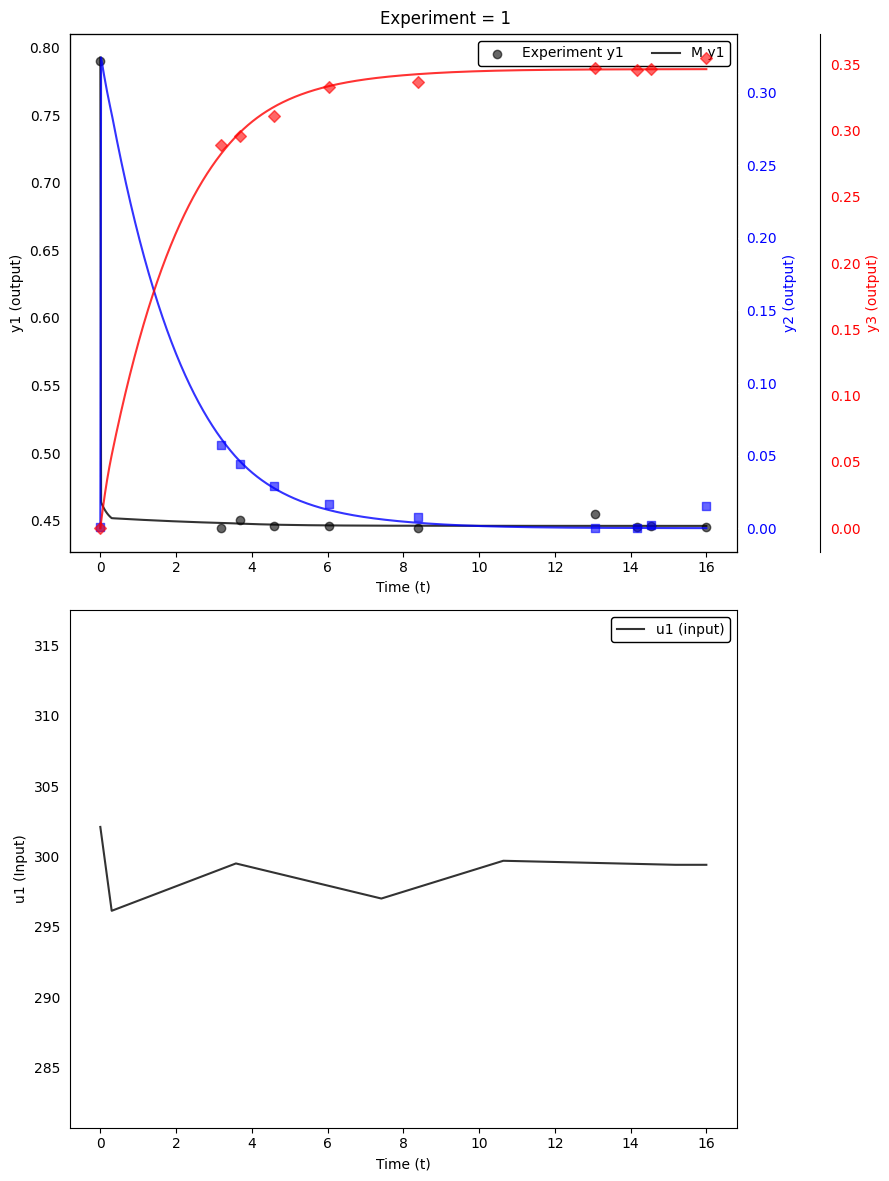

In [8]:
from middoe.log_utils import  save_rounds
round_data={}
save_rounds(round, resultun,  'MBDOE-SEM1', round_data, models, iden_opt, obs, system)

In [9]:
round = 2
des_opt['pp_ob']='SEM'

In [ ]:
from middoe.des_pp import mbdoe_pp
round = 2
designs = mbdoe_pp(des_opt, system, models, round=round, num_parallel_runs=16)

In [ ]:
from middoe.krnl_expera import expera
expera(system, models, insilicos, designs, expr=round, swps=designs['swps'])

In [10]:

from middoe.iden_parmest import parmest
resultpr = parmest(system, models, iden_opt, case='strov')

[INFO] Reading from data.xlsx


In [11]:
round = 2
from middoe.iden_uncert import uncert
uncert_results = uncert(resultpr, system, models, iden_opt)
resultun = uncert_results['results']
obs = uncert_results['obs']

[INFO] Reading from data.xlsx
active_idx: [2 3 4 5]


INFO:middoe.iden_uncert:Conditioning diagnostics: Rank(Q)=4/4, cond(Q)≈1.45e+07, cond(M)≈2.10e+14, λ_min(M)≈1.08e-09; ILL-CONDITIONED


CI: [2.12338708e-02 6.08800226e+03 1.24854377e+04 5.99083765e+04]


[INFO] Reading from data.xlsx


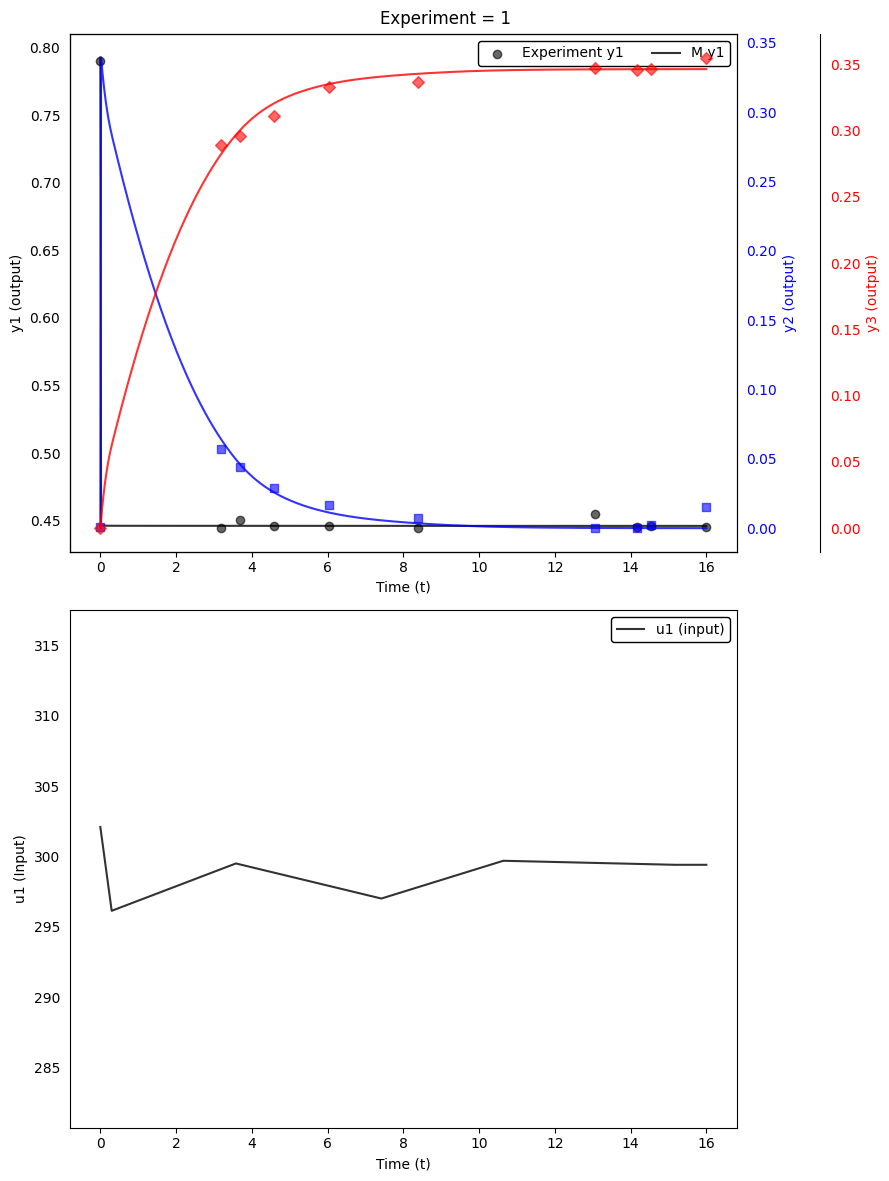

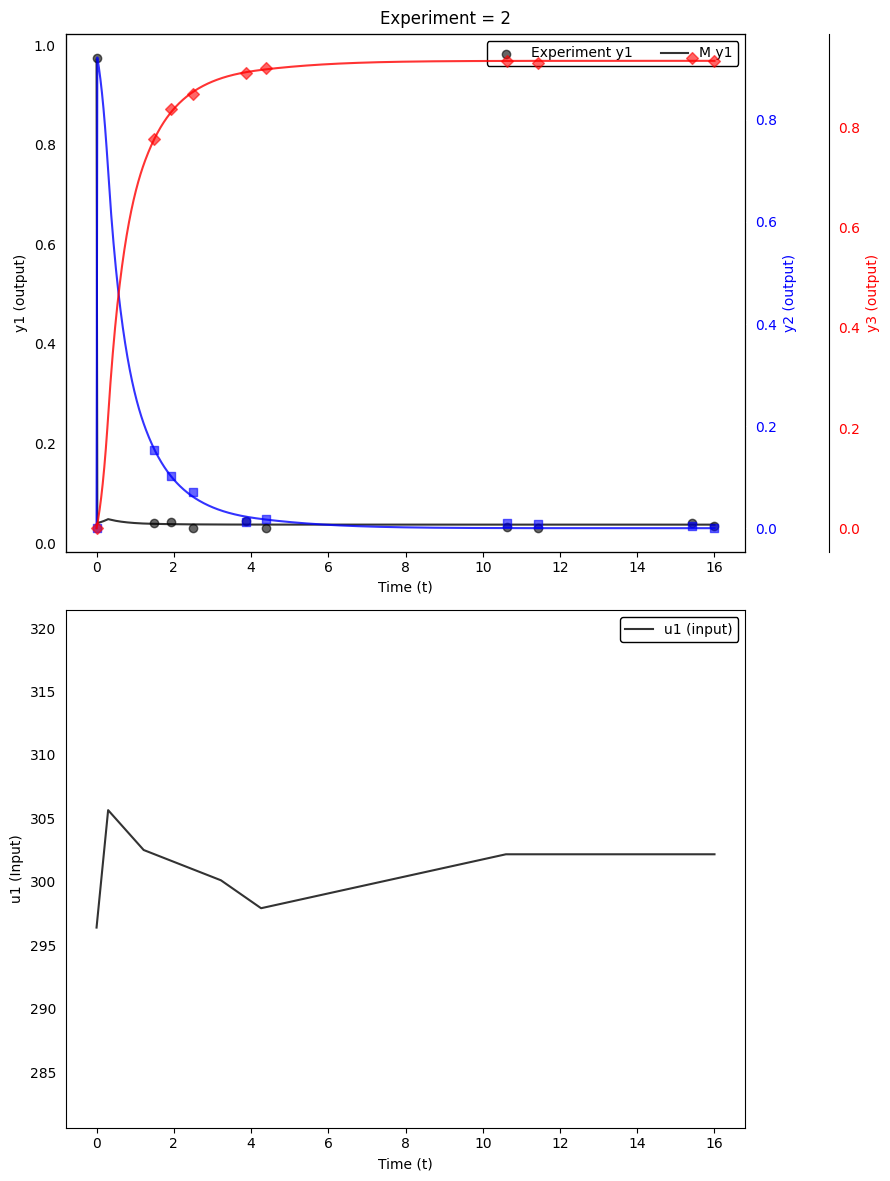

reference t value for model M and round 2: 2.0048792881880564
estimated t values for model M and round 2: [38.33703426 37.17848234  1.31729644  4.84462244]
P-value for model M and round 2: 100.0



{'M': np.float64(2.0048792881880564)}

In [12]:
from middoe.log_utils import  save_rounds
save_rounds(round, resultun,  'MBDOE-SEM2', round_data, models, iden_opt, obs, system)

In [13]:
round = 3

In [ ]:
from middoe.des_pp import mbdoe_pp
round = 3
designs = mbdoe_pp(des_opt, system, models, round=round, num_parallel_runs=16)

In [ ]:
from middoe.krnl_expera import expera
expera(system, models, insilicos, designs, expr=round, swps=designs['swps'])

In [14]:
from middoe.iden_parmest import parmest
resultpr = parmest(system, models, iden_opt, case='strov')
from middoe.iden_uncert import uncert
uncert_results = uncert(resultpr, system, models, iden_opt)
resultun = uncert_results['results']
obs = uncert_results['obs']

[INFO] Reading from data.xlsx
[INFO] Reading from data.xlsx
active_idx: [2 3 4 5]


INFO:middoe.iden_uncert:Conditioning diagnostics: Rank(Q)=4/4, cond(Q)≈1.64e+08, cond(M)≈2.69e+16, λ_min(M)≈2.98e-11; ILL-CONDITIONED


CI: [3.58018559e-03 1.20269553e+03 6.02170610e+02 2.50949490e+02]


[INFO] Reading from data.xlsx


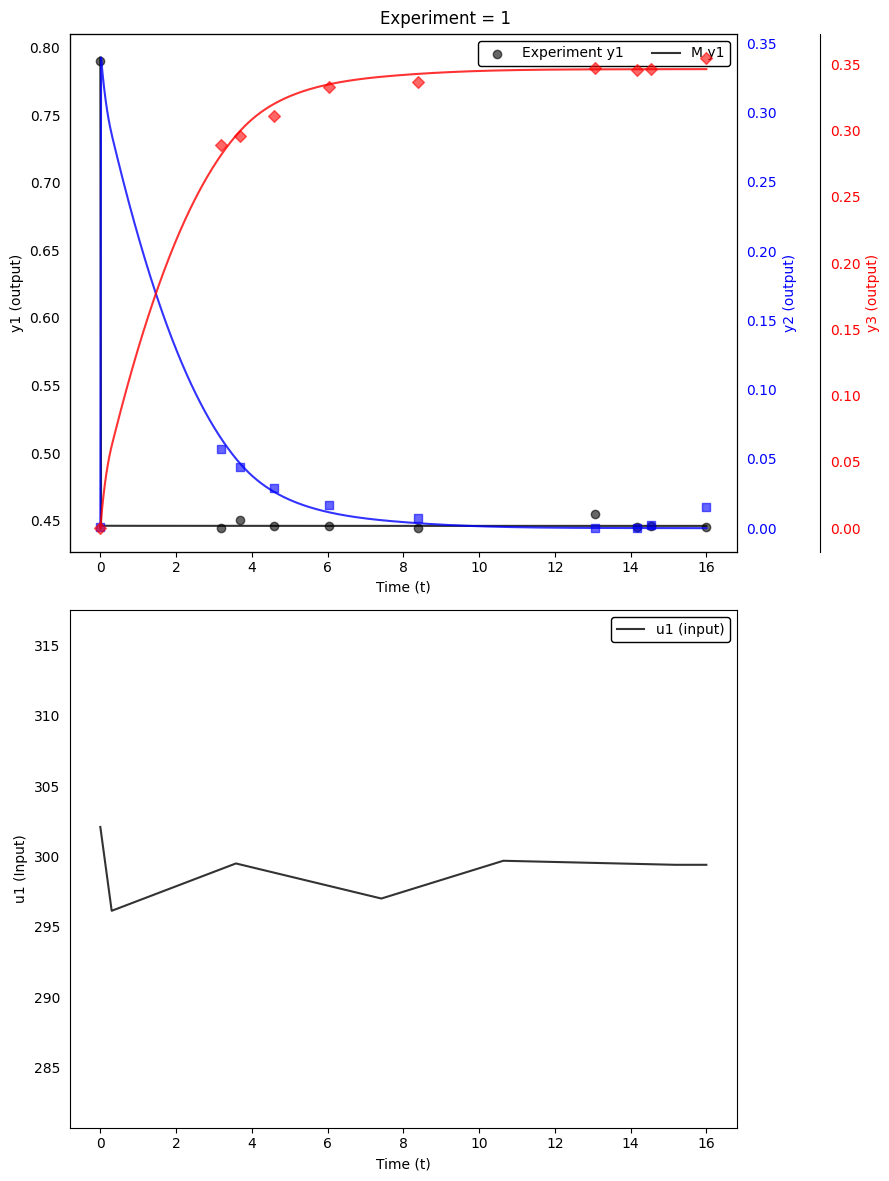

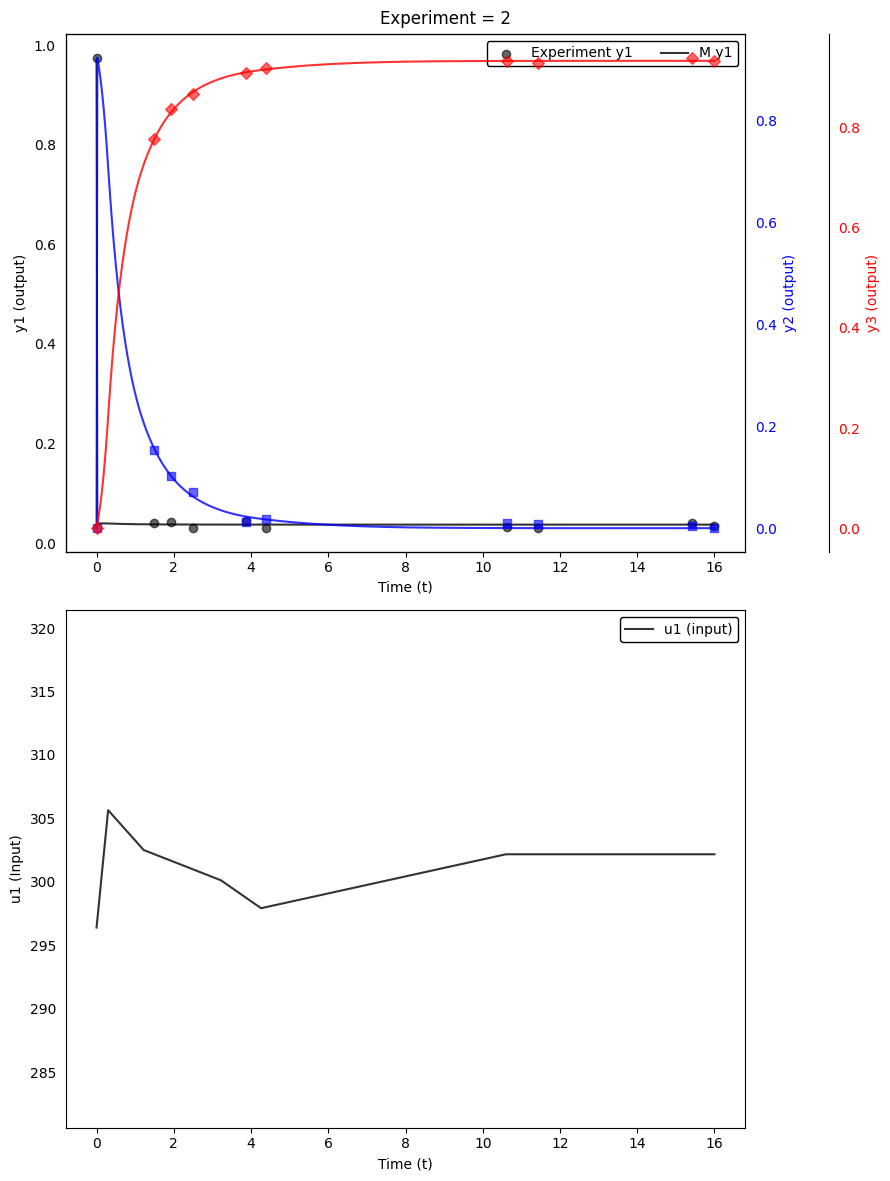

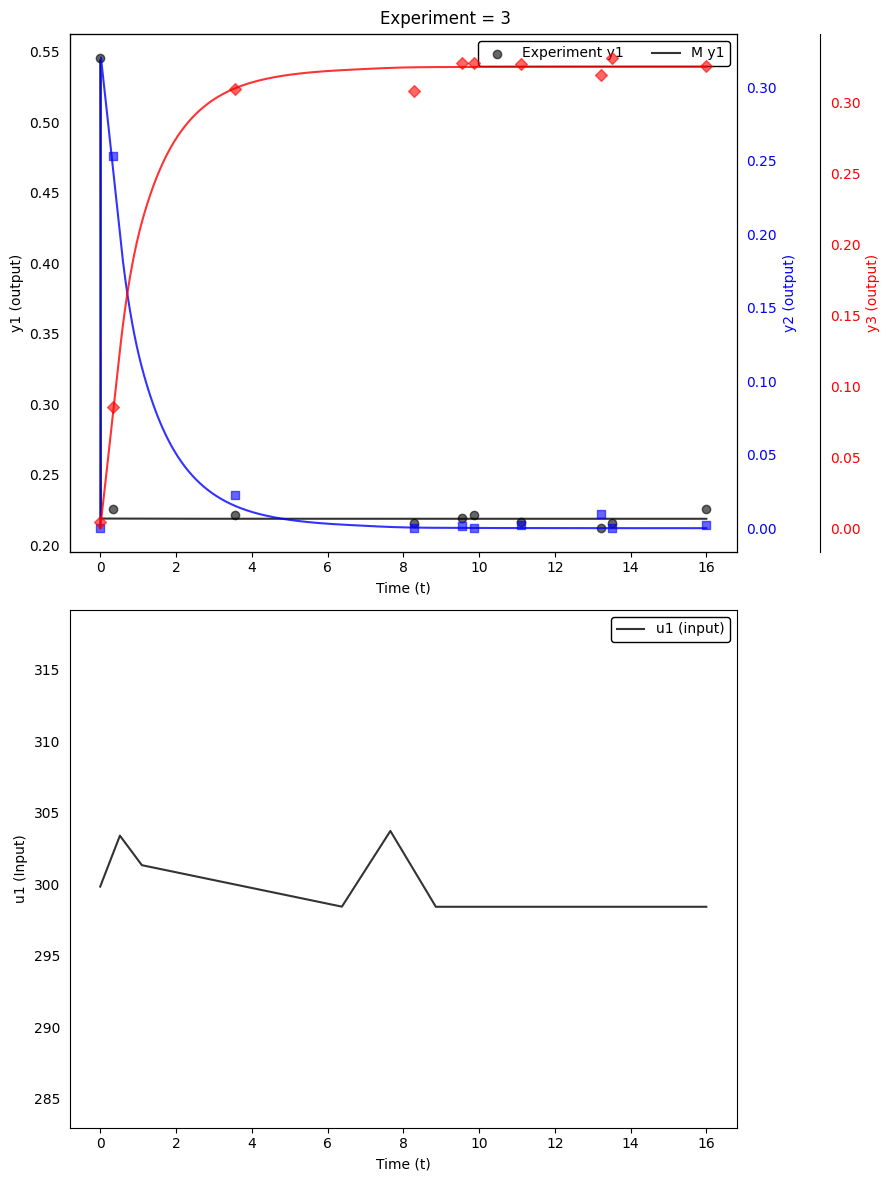

reference t value for model M and round 3: 1.9886096669757087
estimated t values for model M and round 3: [224.52434977 186.04450294  33.01241834 185.33632644]
P-value for model M and round 3: 100.0



{'M': np.float64(1.9886096669757087)}

In [15]:
from middoe.log_utils import  save_rounds
save_rounds(round, resultun,  'MBDOE-SEM3', round_data, models, iden_opt, obs, system)

In [ ]:
from middoe.des_pp import mbdoe_pp
round = 4
designs = mbdoe_pp(des_opt, system, models, round=round, num_parallel_runs=16)

In [ ]:
from middoe.krnl_expera import expera
expera(system, models, insilicos, designs, expr=round, swps=designs['swps'])

In [ ]:
models['mutation']['M'] = [True, True, True, True, True, True]
from middoe.iden_parmest import parmest
resultpr = parmest(system, models, iden_opt, case='strov')
from middoe.iden_uncert import uncert
uncert_results = uncert(resultpr, system, models, iden_opt)
resultun = uncert_results['results']
obs = uncert_results['obs']

In [ ]:
from middoe.sc_estima import estima
ranking, k_optimal_value, rCC_values, J_k_values, best_uncert_result = estima(resultun, system, models, iden_opt, round)

In [ ]:
from middoe.log_utils import  save_rounds
save_rounds(round, resultun,  'MBDOE-SEM4', round_data, models, iden_opt, obs, system, ranking= ranking, k_optimal_value= k_optimal_value, rCC_values= rCC_values, J_k_values= J_k_values,  best_uncert_result= best_uncert_result)

In [ ]:
from middoe.des_pp import mbdoe_pp
round = 5
designs = mbdoe_pp(des_opt, system, models, round=round, num_parallel_runs=16)

In [ ]:
from middoe.krnl_expera import expera
expera(system, models, insilicos, designs, expr=round, swps=designs['swps'])

In [ ]:
models['mutation']['M'] = [True, True, True, True, True, True]
from middoe.iden_parmest import parmest
resultpr = parmest(system, models, iden_opt, case='strov')
from middoe.iden_uncert import uncert
uncert_results = uncert(resultpr, system, models, iden_opt)
resultun = uncert_results['results']
obs = uncert_results['obs']

In [ ]:
from middoe.sc_estima import estima
ranking, k_optimal_value, rCC_values, J_k_values, best_uncert_result = estima(resultun, system, models, iden_opt, round)

In [ ]:
from middoe.log_utils import  save_rounds
save_rounds(round, resultun,  'MBDOE-SEM5', round_data, models, iden_opt, obs, system, ranking= ranking, k_optimal_value= k_optimal_value, rCC_values= rCC_values, J_k_values= J_k_values,  best_uncert_result= best_uncert_result)

In [ ]:
from middoe.des_pp import mbdoe_pp
round = 6
designs = mbdoe_pp(des_opt, system, models, round=round, num_parallel_runs=16)

In [ ]:
from middoe.krnl_expera import expera
expera(system, models, insilicos, designs, expr=round, swps=designs['swps'])

In [ ]:
models['mutation']['M'] = [True, True, True, True, True, True]
from middoe.iden_parmest import parmest
resultpr = parmest(system, models, iden_opt, case='strov')
from middoe.iden_uncert import uncert
uncert_results = uncert(resultpr, system, models, iden_opt)
resultun = uncert_results['results']
obs = uncert_results['obs']

In [ ]:
from middoe.sc_estima import estima
ranking, k_optimal_value, rCC_values, J_k_values, best_uncert_result = estima(resultun, system, models, iden_opt, round)

In [ ]:
from middoe.log_utils import  save_rounds
save_rounds(round, resultun,  'MBDOE-SEM6', round_data, models, iden_opt, obs, system, ranking= ranking, k_optimal_value= k_optimal_value, rCC_values= rCC_values, J_k_values= J_k_values,  best_uncert_result= best_uncert_result)

In [16]:
from middoe.log_utils import save_to_jac
save_to_jac(round_data, purpose="iden")

[INFO] Results saved to: C:\Users\Tadmin\PycharmProjects\middoe\tests\paper3\cs2\SEM+SEM-ext\iden_results.jac


In [17]:
from middoe.log_utils import load_from_jac
results = load_from_jac()
iden = results['iden']

Loaded: iden_results.jac
File not found: sensa_results.jac


In [18]:
from middoe.log_utils import load_from_jac
results = load_from_jac()
iden = results['iden']

from middoe.iden_utils import run_postprocessing
run_postprocessing(
    round_data=results['iden'],
    solvers=['M'],
    selected_rounds=[ 1, 2, 3],
    plot_global_p_and_t=True,
    plot_confidence_spaces=True,
    plot_p_and_t_tests=True,
    export_excel_reports=True,
    plot_estimability=True
)

INFO:middoe.iden_utils:Starting pcomp_plot.


Loaded: iden_results.jac
File not found: sensa_results.jac


ValueError: invalid literal for int() with base 10: '<built-in function round>'